# The Jubilee digital twin: test, acquire, simulate, evaluate

A 2-hour hands-on session. The twin is a Blender copy of the Jubilee: same kinematics, same calibrated toolhead camera, same deck. Today there's a basil plant on the bed.

| # | Exercise | Time | The idea |
|---|---|---|---|
| 0 | Setup | 10 min | Build the scene, take a first virtual picture |
| 1 | Check the experiment before running it | 25 min | A scan plan has a bug. The twin finds it, not the machine |
| 2 | Acquire with the virtual camera | 25 min | Raster scan + the machine makes its own decisions (where to look, where to focus) |
| 3 | Change background and lighting | 20 min | HDRIs in Blender: same geometry, many appearances |
| 4 | Reconstruct with MoGe-2 and evaluate it | 35 min | Single-image 3D from the web, scored against the twin's exact geometry |

**How the notebook talks to the twin.** Every render or check starts Blender headless in the background (5–90 s). Your Python stays here; Blender only does the 3D work. Cells marked ✏️ are for you to edit.

## 0 · Setup (10 min)

Before the session (once per machine):

1. Blender 5.x is on your `PATH` (`blender --version` works in a terminal), or set `JUBILEE_BLENDER_EXE`.
2. `pip install -e jubilee-blender-twin`, then `jubilee-twin setup-scene` has created `pipeline_data/jubilee_working.blend`.
3. This notebook runs in that same environment (e.g. `pixi run jupyter lab`), with `numpy`, `scipy`, `matplotlib`, `pillow` and `plyfile`.

In [1]:
import json
import shutil
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
from scipy.spatial import cKDTree

import workshop_utils as wu

print("Blender     :", shutil.which(wu.BLENDER_EXE) or wu.BLENDER_EXE)
print("Twin folder :", wu.TWIN_DIR)
OUT = wu.OUT_DIR
OUT.mkdir(exist_ok=True)

Blender     : C:\Program Files\Blender Foundation\Blender 5.2\blender.EXE
Twin folder : C:\Users\Alienor\Documents\Projects\Jubilee\jubilee-blender-twin


The twin's working scene holds the machine, its tools and the calibrated `Toolhead_Cam`. We copy it and put a plant on the bed plate (`z_plate_3_V5`), so the plant moves with Z like a real sample would.

In [2]:
PLANT = "basil"          # ✏️ or "monstera"
SCENE = wu.build_scene(PLANT)
SCENE

Scene already built: workshop_basil.blend


WindowsPath('C:/Users/Alienor/Documents/Projects/Jubilee/jubilee-blender-twin/pipeline_data/workshop_basil.blend')

 `wu.open_in_blender(SCENE)` opens the scene in the Blender GUI. Press **N** → **Twin** tab to see the addon panel, and **View>Viewpoint>Camera** to look through the toolhead camera.

**Machine coordinates.** X/Y move the toolhead (and the camera on it), Z moves the bed. A *bigger* Z means the bed is *lower*, so it's further from the camera. Z is limited to 0–340 mm.

First virtual picture, toolhead above the plant:

Rendering 1 image(s) -> C:\Users\Alienor\Documents\Projects\Jubilee\jubilee-blender-twin\workshop\out\ex0
  (Blender finished in 8 s)


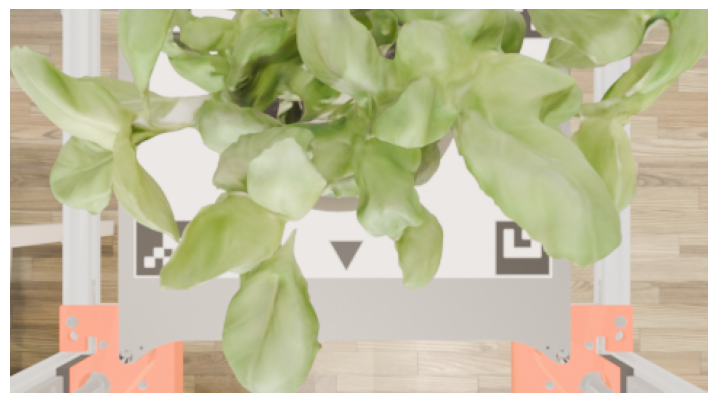

In [4]:
first = wu.render(SCENE, [{"name": "first_look", "x": 147, "y": 195, "z": 330}], OUT / "ex0")
plt.figure(figsize=(9, 5)); plt.imshow(wu.load_image(first[0]["image"])); plt.axis("off");

Change the x, y, z coordinates to move around the space. 

---
## 1 · Check the experiment before running it (25 min)

A colleague wrote this raster scan last month for a **Petri dish**: 15 mm tall, bed raised to Z = 150 so the camera is close. Today the bed holds the basil instead.

**Before running anything: read the plan. What will happen on the real machine?**

In [6]:
PLAN = '''
; Raster scan over the dish, written for a Petri dish (15 mm tall)
G90
G0 X100 Y100 Z150
G1 X200 Y100
G1 X200 Y145
G1 X100 Y145
G1 X100 Y190
G1 X200 Y190
'''

The twin turns the G-code into an animation (one frame per 10 mm of travel), then the existing ray-tracing collision check casts rays from the gantry's convex hull along its motion at every frame. Any scene object the rays hit is a collision.

This is the same `animate_path.py` + `ray_tracing.py` that the addon's **Launch Ray Tracing** button runs.

In [7]:
hits = wu.check_plan(PLAN, SCENE)
print(f"{len(hits)} collision frame(s)")
for h in hits[:8]:
    print(f"  frame {h['frame']:3d}: gantry hits {h['object']!r} at X={h['x']:.0f} Y={h['y']:.0f} Z={h['z']:.0f}")

Plan: 7 G-code lines -> 41 animation frames
  (Blender finished in 15 s)
39 collision frame(s)
  frame   2: gantry hits 'pot' at X=110 Y=100 Z=150
  frame   3: gantry hits 'pot' at X=120 Y=100 Z=150
  frame   4: gantry hits 'pot' at X=130 Y=100 Z=150
  frame   5: gantry hits 'pot' at X=140 Y=100 Z=150
  frame   6: gantry hits 'pot' at X=150 Y=100 Z=150
  frame   7: gantry hits 'pot' at X=160 Y=100 Z=150
  frame   8: gantry hits 'pot' at X=170 Y=100 Z=150
  frame   9: gantry hits 'pot' at X=180 Y=100 Z=150


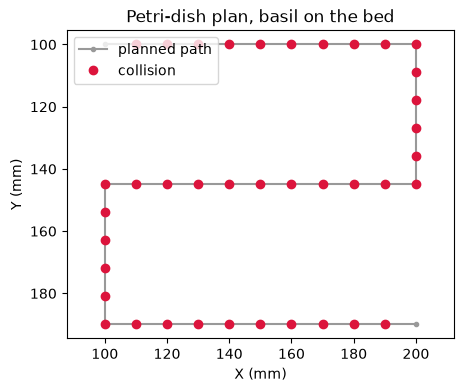

In [8]:
def plot_plan(plan_hits, title):
    # The planned XY path, collision frames in red.
    path = np.loadtxt(wu.PIPELINE_DIR / "pathout.csv", delimiter=",", ndmin=2)
    bad = [h["frame"] - 1 for h in plan_hits]
    plt.figure(figsize=(5, 4))
    plt.plot(path[:, 0], path[:, 1], "-o", ms=3, color="0.6", label="planned path")
    plt.plot(path[bad, 0], path[bad, 1], "o", color="crimson", label="collision")
    plt.gca().invert_yaxis(); plt.axis("equal")
    plt.xlabel("X (mm)"); plt.ylabel("Y (mm)"); plt.title(title); plt.legend()

plot_plan(hits, "Petri-dish plan, basil on the bed")

What the toolhead camera would see at that height, a moment before the crash:

Rendering 1 image(s) -> C:\Users\Alienor\Documents\Projects\Jubilee\jubilee-blender-twin\workshop\out\ex1
  (Blender finished in 10 s)


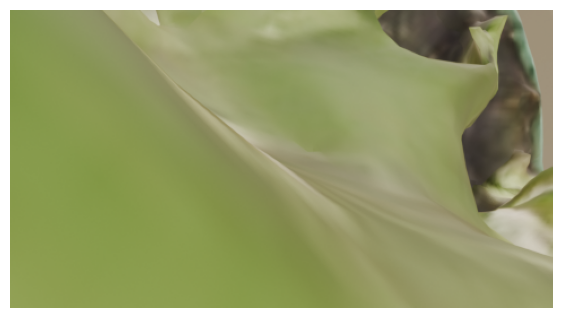

In [9]:
crash = wu.render(SCENE, [{"name": "crash_view", "x": 147, "y": 145, "z": 150}], OUT / "ex1")
plt.figure(figsize=(7, 4)); plt.imshow(wu.load_image(crash[0]["image"])); plt.axis("off");

### ✏️ Your turn: fix the plan

Change the plan so the scan is safe, then re-run the check. Keep the camera as close as you safely can, because that gives more pixels on the plant.

Plan: 7 G-code lines -> 41 animation frames
  (Blender finished in 15 s)
SAFE ✅


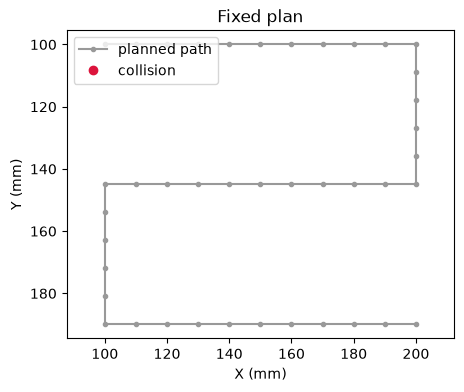

In [11]:
FIXED_PLAN = PLAN.replace("Z150", "Z150")   # CHANGE VALUE HERE

fixed_hits = wu.check_plan(FIXED_PLAN, SCENE)
print("SAFE ✅" if not fixed_hits else f"Still {len(fixed_hits)} collision frame(s) ❌")
plot_plan(fixed_hits, "Fixed plan")

### Bonus: ask the twin a question you can't safely ask the machine

*What is the lowest safe Z for this plant?* On hardware you'd find out by crashing. In the twin, a bisection takes about a minute.

In [ ]:
def is_safe(z):
    return not wu.check_plan(PLAN.replace("Z150", f"Z{z:.0f}"), SCENE)

lo, hi = 150, 330            # lo collides, hi is safe
while hi - lo > 5:
    mid = (lo + hi) / 2
    safe = is_safe(mid)
    print(f"Z = {mid:.0f}  ->  {'safe' if safe else 'collision'}")
    lo, hi = (lo, mid) if safe else (mid, hi)
print(f"\nLowest safe Z ≈ {hi:.0f} mm. Add a margin before using it on the machine.")

**Discussion**
- The check only knows what's *in* the twin. A plant that grew since the scene was built is invisible to it. How would you keep the twin up to date? (Hint: Exercise 4.)
- Why is this check worth running for *every* plan, not just new ones?

---
## 2 · Acquire with the virtual camera (25 min)

Now script an acquisition, with two decisions taken by the machine instead of by you:

1. **Raster** over the bed → score every tile → *go where the plant is*.
2. **Z-stack** on that tile → score sharpness → *pick the best focus*.

To make focus matter, the virtual camera gets a real lens behaviour: depth of field with a fixed focus distance (like a fixed-focus objective). Moving the bed in Z moves the plant in and out of focus.

In [13]:
OPTICS = {"fstop": 4.0, "focus_distance": 0.14}   # aperture, focus distance in metres

def raster(x0, x1, nx, y0, y1, ny, z):
    # Serpentine raster: one job per tile.
    jobs = []
    for j, y in enumerate(np.linspace(y0, y1, ny)):
        xs = np.linspace(x0, x1, nx)
        for x in (xs if j % 2 == 0 else xs[::-1]):
            jobs.append({"name": f"tile_x{x:.0f}_y{y:.0f}", "x": float(x), "y": float(y), "z": z, **OPTICS})
    return jobs

tiles = raster(60, 230, 3, 70, 220, 3, z=310)   # ✏️ try a finer grid
tiles = wu.render(SCENE, tiles, OUT / "ex2" / "raster")

Rendering 9 image(s) -> C:\Users\Alienor\Documents\Projects\Jubilee\jubilee-blender-twin\workshop\out\ex2\raster
  (Blender finished in 19 s)


In [ ]:
def show_tiles(tiles, scores=None):
    xs = sorted({t["x"] for t in tiles}); ys = sorted({t["y"] for t in tiles})
    fig, axes = plt.subplots(len(ys), len(xs), figsize=(3.2 * len(xs), 1.9 * len(ys)), squeeze=False)
    for t in tiles:
        ax = axes[ys.index(t["y"]), xs.index(t["x"])]
        ax.imshow(wu.load_image(t["image"])); ax.set_xticks([]); ax.set_yticks([])
        label = f"X{t['x']:.0f} Y{t['y']:.0f}"
        if scores is not None:
            label += f"  score {scores[t['name']]:.2f}"
        ax.set_title(label, fontsize=9)
    plt.tight_layout()

show_tiles(tiles)

### Decision 1: where is the plant?

A classic plant-segmentation index: **excess green**, `ExG = 2g − r − b` on chromaticity-normalised colours. A pixel with ExG above a threshold counts as plant, and the tile score is the plant fraction.

In [ ]:
def plant_fraction(rgb, threshold=0.10):
    rgb = rgb.astype(float)
    chroma = rgb / (rgb.sum(-1, keepdims=True) + 1e-6)
    r, g, b = chroma[..., 0], chroma[..., 1], chroma[..., 2]
    exg = 2 * g - r - b
    return (exg > threshold).mean()

coverage = {t["name"]: plant_fraction(wu.load_image(t["image"])) for t in tiles}
best_tile = max(tiles, key=lambda t: coverage[t["name"]])
show_tiles(tiles, coverage)
print("Most plant in", best_tile["name"])

### Decision 2: autofocus

Acquire a Z-stack on the chosen tile and let a sharpness score choose. The simplest robust score is the **variance of the Laplacian**: in-focus images have strong edges, so the second derivative varies a lot.

In [ ]:
def sharpness(rgb):
    gray = rgb.astype(float).mean(-1)
    return ndimage.laplace(gray).var()

Z_STACK = np.arange(220, 341, 15)   # ✏️
stack = wu.render(SCENE, [{"name": f"z{z}", "x": best_tile["x"], "y": best_tile["y"], "z": int(z), **OPTICS}
                          for z in Z_STACK], OUT / "ex2" / "zstack")
scores = np.array([sharpness(wu.load_image(s["image"])) for s in stack])
best = stack[int(scores.argmax())]
print(f"Best focus at Z = {best['z']} mm")

In [ ]:
fig = plt.figure(figsize=(13, 3.6))
ax = fig.add_subplot(1, 3, 1)
ax.plot(Z_STACK, scores, "-o"); ax.axvline(best["z"], color="crimson", ls="--")
ax.set_xlabel("bed Z (mm)"); ax.set_ylabel("sharpness (var. of Laplacian)")
worst = stack[int(scores.argmin())]
for i, (s, label) in enumerate([(best, "chosen"), (worst, "worst")]):
    ax = fig.add_subplot(1, 3, i + 2); ax.imshow(wu.load_image(s["image"])); ax.axis("off")
    ax.set_title(f"{label}: Z = {s['z']}")
plt.tight_layout()

### ✏️ Your turn (pick one)

- **Fewer images.** A real Z-stack costs time and light dose. Write a coarse-to-fine search (e.g. 30 mm steps, then 5 mm steps around the best) and count how many images you need.
- **Another score.** Try Tenengrad (`ndimage.sobel` magnitude squared, averaged). Does it pick the same Z?
- **Safety first.** Your raster is a plan too. Turn `tiles` into G-code and pass it to `wu.check_plan` from Exercise 1.

In [ ]:
# ✏️ your code here

---
## 3 · Change background and lighting (20 min)

In Blender, the **World** lights the scene. An **HDRI** is a 360° photo of a real place, and it does two jobs at once: it *lights* the plant, and it is the *background* the camera sees (the wooden floor so far is the kitchen HDRI's floor).

Swap the HDRI and you get a new appearance with **identical geometry**. That's the basis of synthetic datasets: depth, masks and camera poses stay exactly the same, so the annotations come for free.

Put your HDRIs (`.hdr` or `.exr`, e.g. 1k files from [polyhaven.com/hdris](https://polyhaven.com/hdris)) in `workshop/hdri/`. Two CC0 Poly Haven HDRIs are already there.

In [ ]:
HDRI_DIR = wu.WORKSHOP_DIR / "hdri"
HDRIS = sorted([*HDRI_DIR.glob("*.hdr"), *HDRI_DIR.glob("*.exr")])
for h in HDRIS:
    print(h.name)

### 3a · In the Blender GUI (demo, ~10 min)

`wu.open_in_blender(SCENE)`, then:

1. **Look through the camera.** In the Outliner, right-click `Toolhead_Cam` → *Set Active Camera*; hover the 3D view and press **Numpad 0**. Switch the viewport to **Rendered** shading (**Z** → Rendered) to see lighting live.
2. **Change the HDRI.** Properties panel → **World** tab (red globe) → *Surface* → *Color*. Click the yellow dot → **Environment Texture** → **Open** → pick an `.hdr`.
3. **Change the intensity.** Same panel → *Strength*. 3 is the twin's default, 0.5 gives a dim room.
4. **Rotate the light.** Go to the **Shading** workspace, set the node editor to **World**. Add *Texture Coordinate* → *Mapping* → into the Environment Texture's *Vector* (or select the texture node and press **Ctrl+T** with the Node Wrangler add-on). Change *Mapping → Rotation Z*: shadows and highlights move around the plant.
5. **Plain background, same lighting.** Add a *Light Path* node, a second *Background* (any colour) and a *Mix Shader*. Wire *Is Camera Ray* → *Fac*, HDRI background → first shader input, plain colour → second. The camera now sees the flat colour, but the plant is still lit by the HDRI.
6. **F12** renders through the toolhead camera.

### 3b · The same, from Python

Each GUI action above is one key of a render job: `hdri`, `strength`, `rotation_deg`, `plain_background`.

In [ ]:
VIEW = {"x": 147, "y": 145, "z": 340}

looks = [
    {"name": "default_kitchen"},
    {"name": "hdri_A", "hdri": str(HDRIS[0])},
    {"name": "hdri_B", "hdri": str(HDRIS[1])},
    {"name": "hdri_B_rotated", "hdri": str(HDRIS[1]), "rotation_deg": 120},
    {"name": "hdri_B_dim", "hdri": str(HDRIS[1]), "strength": 0.8},
    {"name": "hdri_B_plain_bg", "hdri": str(HDRIS[1]), "plain_background": [0.05, 0.05, 0.05]},
]
looks = wu.render(SCENE, [{**VIEW, **look} for look in looks], OUT / "ex3")

fig, axes = plt.subplots(2, 3, figsize=(15, 5.5))
for ax, look in zip(axes.flat, looks):
    ax.imshow(wu.load_image(look["image"])); ax.set_title(look["name"]); ax.axis("off")
plt.tight_layout()

### ✏️ Your turn

Design a small augmentation set, for example 2 HDRIs × 3 rotations × 2 strengths = 12 images, and render it. Which variations change the image the most? Which ones would make a plant-segmentation model more robust?

Keep one look you like. In Exercise 4 you can check whether lighting changes what MoGe-2 reconstructs.

In [ ]:
# ✏️ your code here

---
## 4 · Reconstruct with MoGe-2 and evaluate it (35 min)

[MoGe-2](https://huggingface.co/spaces/Ruicheng/MoGe-2) predicts a **metric 3D point map from a single image**: for every pixel, an (x, y, z) in metres in the camera frame. How good is it on our plant? On a real plant you can't answer that, because nobody knows the true geometry. In the twin we do: we can ray-cast the exact surface seen by every pixel.

### 4.1 · Render the input image and its ground truth (~2 min)

In [ ]:
EX4 = OUT / "ex4"
LOOK = {}   # ✏️ e.g. {"hdri": str(HDRIS[0])} to test another lighting from Exercise 3

shot = wu.render(SCENE, [{"name": "moge_input", **VIEW, **LOOK, "ground_truth": True}], EX4, percent=50)[0]
gt = np.load(shot["ground_truth"])
K = gt["K"]
print("Image to upload:", shot["image"])
print("Intrinsics K (pixels):\n", K.round(1))

What the twin gives for free, per pixel: **depth**, the **plant mask**, the 3D **point map**, plus **K** and the camera pose (`gt["cam_to_world"]`). It also gives the plant's *full* mesh, including the parts no camera above can see.

In [ ]:
rgb = wu.load_image(shot["image"])
depth, mask, points = gt["depth"], gt["mask"], gt["points"]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
axes[0].imshow(rgb); axes[0].set_title("render")
im = axes[1].imshow(np.where(depth > 0, depth * 100, np.nan), cmap="turbo"); axes[1].set_title("depth (cm)")
plt.colorbar(im, ax=axes[1], fraction=0.03)
axes[2].imshow(mask, cmap="gray"); axes[2].set_title("plant mask")
for ax in axes: ax.axis("off")
plt.tight_layout()

gt_visible = points[mask]                 # the surface the camera sees (OpenCV frame: x right, y down, z forward)
gt_full = gt["plant_vertices"]            # every vertex of the plant, hidden ones included
wu.write_ply(EX4 / "gt_plant_visible.ply", gt_visible, rgb[mask])
wu.write_ply(EX4 / "gt_plant_full.ply", gt_full)
print(f"{len(gt_visible):,} visible plant points, {len(gt_full):,} mesh vertices")

### 4.2 · Run MoGe-2 online

1. Open **https://huggingface.co/spaces/Ruicheng/MoGe-2** (sign in to Hugging Face if the GPU quota complains).
2. Upload `workshop/out/ex4/moge_input.png` and run it with the default settings.
3. In the **Download** tab, save **`pointcloud.ply`** to `workshop/out/ex4/moge/pointcloud.ply`. Download it promptly, because the demo deletes its files after a few minutes.

While it runs, look at the 3D viewer. Does the plant look right? Is the bed flat? Are leaves separated from each other?

In [ ]:
MOGE_PLY = EX4 / "moge" / "pointcloud.ply"
MOGE_PLY.parent.mkdir(exist_ok=True)
assert MOGE_PLY.exists(), f"Put MoGe's pointcloud.ply here first: {MOGE_PLY}"

moge_raw = wu.read_ply(MOGE_PLY)
print(f"{len(moge_raw):,} MoGe points")

### 4.3 · Put both clouds in the same frame

The demo exports its point cloud multiplied by `[1, −1, −1]` (glTF/OpenGL convention: y up, z backwards). Undo it, and MoGe's points are in the same **OpenCV camera frame** as our ground truth. Same camera, same image, so no registration is needed.

In [ ]:
moge = moge_raw * np.array([1.0, -1.0, -1.0])

def side_views(clouds, title, n=20000):
    # Front (x-y) and side (z-y) views of several clouds, subsampled.
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    rng = np.random.default_rng(0)
    for (name, pts, color) in clouds:
        p = pts[rng.choice(len(pts), min(n, len(pts)), replace=False)] * 100
        axes[0].scatter(p[:, 0], p[:, 1], s=0.3, c=color, label=name)
        axes[1].scatter(p[:, 2], p[:, 1], s=0.3, c=color)
    axes[0].set_xlabel("x (cm)"); axes[0].set_ylabel("y (cm)"); axes[0].set_title("seen from the camera")
    axes[1].set_xlabel("z = distance from camera (cm)"); axes[1].set_title("seen from the side")
    for ax in axes: ax.invert_yaxis(); ax.set_aspect("equal")
    axes[0].legend(markerscale=20); fig.suptitle(title)

side_views([("MoGe-2 (whole image)", moge, "tab:orange"), ("twin: plant, visible", gt_visible, "tab:green")],
           "Raw MoGe output vs ground truth")

### 4.4 · Is MoGe-2 really metric?

MoGe-2 claims absolute scale. Take the MoGe points that project inside the plant mask, using the twin's `K`, and compare median distances to the camera:

In [ ]:
def in_mask(pts, K, mask, dilate=0):
    # True for points whose projection with K lands inside the (dilated) mask.
    m = ndimage.binary_dilation(mask, iterations=dilate) if dilate else mask
    z = pts[:, 2]
    ok = z > 0
    u = np.round(K[0, 0] * pts[:, 0] / np.where(ok, z, 1) + K[0, 2]).astype(int)
    v = np.round(K[1, 1] * pts[:, 1] / np.where(ok, z, 1) + K[1, 2]).astype(int)
    ok &= (u >= 0) & (u < m.shape[1]) & (v >= 0) & (v < m.shape[0])
    keep = np.zeros(len(pts), bool)
    keep[ok] = m[v[ok], u[ok]]
    return keep

on_plant = in_mask(moge, K, mask)
scale = np.median(gt_visible[:, 2]) / np.median(moge[on_plant, 2])
print(f"median distance  twin: {np.median(gt_visible[:, 2]) * 100:.1f} cm   MoGe-2: {np.median(moge[on_plant, 2]) * 100:.1f} cm")
print(f"MoGe-2 scale error: {(1 / scale - 1) * 100:+.1f} %")

### 4.5 · Keep only the plant

The mask alone isn't a clean crop. MoGe's own field of view is never exactly ours, so we dilate the mask a little to keep the leaf edges. But a dilated mask also catches bed pixels next to every leaf. Depth separates them: after scale alignment, keep only points within 1.5 cm of the plant's true depth range.

In [ ]:
moge_scaled = moge * scale                       # remove the global scale error to look at shape only
z_min, z_max = gt_visible[:, 2].min() - 0.015, gt_visible[:, 2].max() + 0.015
keep = in_mask(moge_scaled, K, mask, dilate=8) & (moge_scaled[:, 2] > z_min) & (moge_scaled[:, 2] < z_max)

moge_plant = moge[keep]            # as MoGe predicted it
moge_aligned = moge_scaled[keep]   # scale-aligned
print(f"{keep.sum():,} MoGe points on the plant")

### 4.6 · How good is the shape?

For every MoGe point, the distance to the nearest true surface point (**accuracy**). For every true point, the distance to the nearest MoGe point (**completeness**). Their average is the **Chamfer distance**. The **F-score** at τ = 5 mm combines the fraction of points within 5 mm in both directions.

In [ ]:
def compare(pred, true, tau=0.005):
    d_pred = cKDTree(true).query(pred)[0]     # accuracy: pred -> true
    d_true = cKDTree(pred).query(true)[0]     # completeness: true -> pred
    precision, recall = (d_pred < tau).mean(), (d_true < tau).mean()
    return {
        "accuracy_mm": 1000 * np.median(d_pred),
        "completeness_mm": 1000 * np.median(d_true),
        "chamfer_mm": 1000 * (d_pred.mean() + d_true.mean()) / 2,
        "F@5mm": 2 * precision * recall / (precision + recall + 1e-9),
    }, d_pred

raw_metrics, _ = compare(moge_plant, gt_visible)
metrics, err = compare(moge_aligned, gt_visible)
print(f"{'':16s}{'raw':>10s}{'scale-aligned':>16s}")
for k in metrics:
    print(f"{k:16s}{raw_metrics[k]:10.2f}{metrics[k]:16.2f}")

In [ ]:
side_views([("MoGe-2, plant, scale-aligned", moge_aligned, "tab:orange"), ("twin: plant, visible", gt_visible, "tab:green")],
           "After cropping and scale alignment")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
p = moge_aligned * 100
sc = axes[0].scatter(p[:, 0], p[:, 1], c=err * 1000, s=0.3, cmap="magma", vmin=0, vmax=15)
axes[0].invert_yaxis(); axes[0].set_aspect("equal"); axes[0].set_title("error per MoGe point (mm)")
plt.colorbar(sc, ax=axes[0])
axes[1].hist(err * 1000, bins=60, range=(0, 30)); axes[1].set_xlabel("distance to true surface (mm)")
axes[1].set_title("error distribution")
plt.tight_layout()

# Open these side by side in CloudCompare or MeshLab:
colors = (plt.cm.magma(np.clip(err / 0.015, 0, 1))[:, :3] * 255).astype(np.uint8)
wu.write_ply(EX4 / "moge_plant_error.ply", moge_aligned, colors)
print("Wrote", EX4 / "moge_plant_error.ply", "and", EX4 / "gt_plant_visible.ply")

### 4.7 · What a single image can't see

In [ ]:
side_views([("twin: full plant mesh", gt_full, "0.75"), ("MoGe-2", moge_aligned, "tab:orange")],
           "Hidden geometry: everything grey without orange is invisible from this viewpoint")

### ✏️ Discussion and experiments

- Where are the errors largest: leaf edges, overlapping leaves, the soil? Why?
- How large is the scale error compared to the shape error? Which one matters for measuring leaf area? For collision checking?
- **Lighting robustness:** set `LOOK` in 4.1 to another HDRI from Exercise 3, upload again, and compare the metrics. The ground truth didn't move; only the appearance did.
- **Close the loop:** MoGe gives a plant surface from one image. Could it update the twin's plant before Exercise 1's collision check? What margin would you add, given the errors you measured?

---
## Wrap-up

| Exercise | What the twin gave us |
|---|---|
| 1 | A crash we didn't have, and the lowest safe Z without touching the machine |
| 2 | A scripted acquisition that decides where to look and where to focus |
| 3 | Unlimited appearance variations of the same, exactly known, scene |
| 4 | An exact yardstick for a 3D foundation model |

All outputs are in `workshop/out/`.